## Read embeddings

In [1]:
import pandas as pd
MODELS_DESCRIPTIONS = {
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
    "mix_of_alleles_balanced":
    {
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "path": "experiment_results/alleles_with_groups_balanced/",
        "states": 25,
        "params_string": "5-min_iters",
        "target_lengths": [9, 10]
    }

}
selected_model = MODELS_DESCRIPTIONS["mix_of_alleles"]


In [2]:

selected_alleles = selected_model['alleles']
states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = 0
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [3]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [4]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [5]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
CPU times: total: 23 s
Wall time: 23.4 s


# Scanpy

In [6]:
target_df = per_model_type_train_embeddings['bwv']

In [7]:
dropped_columns = target_df.drop(columns=['allele', 'peptide']).copy()
transposed = dropped_columns.T.copy()

In [8]:
target_df

,0,1,2,3,4,5,6,7,8,9,...,1585,1586,1587,1588,1589,1590,1591,1592,allele,peptide
SFDIQLTSV,-0.525781,-0.558399,-0.445194,-0.477812,-0.393495,-0.393589,-0.465398,-0.465492,-0.585374,-0.617991,...,-0.717829,-0.659438,-0.593760,-0.699987,-0.715404,-0.630531,-0.701759,-0.735208,HLA-A*01:01,SFDIQLTSV
TTEILRSML,-0.403412,-0.471762,-0.471547,-0.539896,-0.456327,-0.456420,-0.386187,-0.386281,-0.472255,-0.540605,...,-0.668725,-0.605807,-0.913050,-0.803120,-0.655147,-0.834815,-0.756406,-0.670186,HLA-A*01:01,TTEILRSML
ALNDTWKMEK,-0.478088,-0.437717,-0.530522,-0.490150,-0.489915,-0.397902,-0.426743,-0.334730,-0.543107,-0.502736,...,-0.739907,-0.692268,-0.655200,-0.702145,-0.737723,-0.765234,-0.843700,-0.756646,HLA-A*03:01,ALNDTWKMEK
ALAAAAAAAK,-0.362746,-0.314190,-0.435340,-0.386784,-0.374567,-0.282554,-0.442989,-0.350976,-0.427295,-0.378738,...,-0.768096,-0.566033,-0.755969,-0.799221,-0.605313,-0.811250,-0.886022,-0.638475,HLA-A*03:01,ALAAAAAAAK
LYDKDAVYV,-0.538197,-0.570815,-0.610791,-0.643409,-0.421703,-0.421797,-0.493718,-0.493812,-0.596255,-0.628873,...,-0.647676,-0.647497,-0.603350,-0.568137,-0.702314,-0.712433,-0.652261,-0.708652,HLA-A*01:01,LYDKDAVYV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FIFQSSMTK,-0.533246,-0.435622,-0.458830,-0.361206,-0.444857,-0.444951,-0.388268,-0.388362,-0.600204,-0.502580,...,-0.548574,-0.671730,-0.703474,-0.653894,-0.635975,-0.769098,-0.696860,-0.738430,HLA-A*03:01,FIFQSSMTK
QLYKEQLAK,-0.387066,-0.289442,-0.456115,-0.358491,-0.380576,-0.380670,-0.304621,-0.304715,-0.369552,-0.271928,...,-0.611254,-0.679642,-0.772493,-0.809094,-0.634638,-0.837059,-0.905181,-0.752084,HLA-A*03:01,QLYKEQLAK
LLNRPLWAK,-0.473179,-0.375555,-0.392593,-0.294969,-0.323792,-0.323886,-0.373212,-0.373306,-0.540195,-0.442571,...,-0.580566,-0.613935,-0.658013,-0.703100,-0.662632,-0.687887,-0.764495,-0.686378,HLA-A*03:01,LLNRPLWAK
KVPVVLLKK,-0.462836,-0.365212,-0.382249,-0.284625,-0.442473,-0.442567,-0.366518,-0.366612,-0.443545,-0.345921,...,-0.612705,-0.818142,-0.812638,-0.859701,-0.771797,-0.729165,-0.807749,-0.753747,HLA-A*03:01,KVPVVLLKK


In [9]:
import scanpy as sc
import anndata as ad
import numpy as np

In [10]:
obs = pd.DataFrame({"peptide": target_df.index.values, "allele": target_df['allele'].values, "length": target_df.index.str.len().values})
var = pd.DataFrame({"path":target_df.columns.drop(['allele', 'peptide'])})
X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)

In [11]:
adata = ad.AnnData(X, obs=obs, var=var, dtype='float')

d:\tools\python\anaconda\envs\biopython\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [12]:
adata

AnnData object with n_obs × n_vars = 13336 × 1593
    obs: 'peptide', 'allele', 'length'
    var: 'path'

In [13]:
adata.obs

,peptide,allele,length
0,SFDIQLTSV,HLA-A*01:01,9
1,TTEILRSML,HLA-A*01:01,9
2,ALNDTWKMEK,HLA-A*03:01,10
3,ALAAAAAAAK,HLA-A*03:01,10
4,LYDKDAVYV,HLA-A*01:01,9
...,...,...,...
13331,FIFQSSMTK,HLA-A*03:01,9
13332,QLYKEQLAK,HLA-A*03:01,9
13333,LLNRPLWAK,HLA-A*03:01,9
13334,KVPVVLLKK,HLA-A*03:01,9


In [14]:
adata.var

,path
0,0
1,1
2,2
3,3
4,4
...,...
1588,1588
1589,1589
1590,1590
1591,1591


In [15]:
adata.X

array([[0.59109352, 0.57212452, 0.64069983, ..., 0.53230888, 0.49571278,
        0.47940556],
       [0.66803671, 0.62390219, 0.62403627, ..., 0.43395485, 0.46935027,
        0.5116136 ],
       [0.61996747, 0.64550868, 0.58829792, ..., 0.46522498, 0.43011624,
        0.46923748],
       ...,
       [0.62301831, 0.68690765, 0.67530384, ..., 0.50263713, 0.46556912,
        0.5033962 ],
       [0.62949583, 0.69404942, 0.68232497, ..., 0.48231151, 0.4458606 ,
        0.47059969],
       [0.64753404, 0.59068737, 0.70187701, ..., 0.51424008, 0.47719157,
        0.45157218]])

## 1. Normalize

In [16]:
sc.pp.normalize_total(adata) # Total-count normalize (library-size correct) the data matrix X to 10,000 reads per cell, so that counts become comparable among cells.
sc.pp.log1p(adata) # log-normalization

In [17]:
adata.X

array([[0.4573679 , 0.44551876, 0.48770711, ..., 0.42018135, 0.39631261,
        0.3854904 ],
       [0.50260413, 0.47615834, 0.47623975, ..., 0.35361044, 0.37761421,
        0.40554069],
       [0.49827745, 0.5143151 , 0.47802779, ..., 0.39519427, 0.37024973,
        0.39800591],
       ...,
       [0.47587464, 0.51397041, 0.50715831, ..., 0.3998945 , 0.37528648,
        0.40039214],
       [0.4801918 , 0.51855176, 0.51169316, ..., 0.38680251, 0.36226112,
        0.37898273],
       [0.48964419, 0.45506498, 0.52161875, ..., 0.40659359, 0.38222996,
        0.36502827]])

## 2. Highly variable features
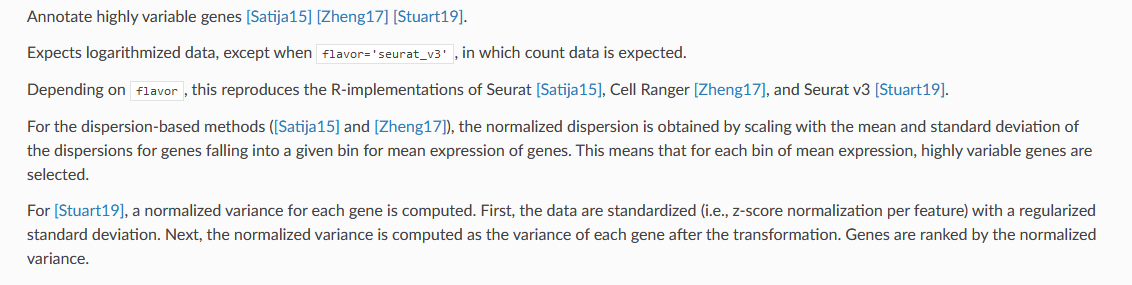
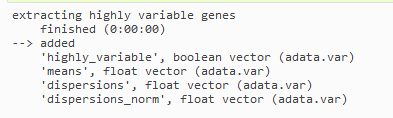
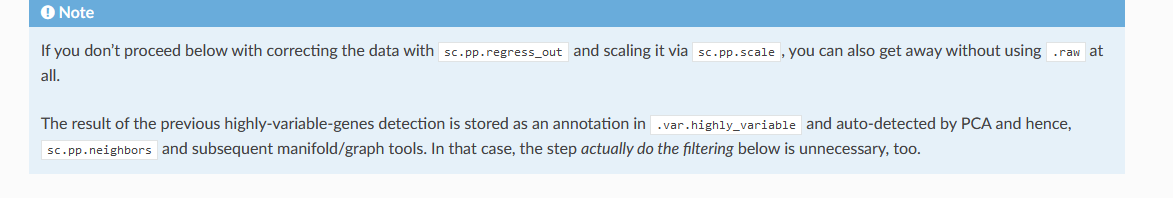



<AxesSubplot:xlabel='mean expressions of genes', ylabel='dispersions of genes (not normalized)'>

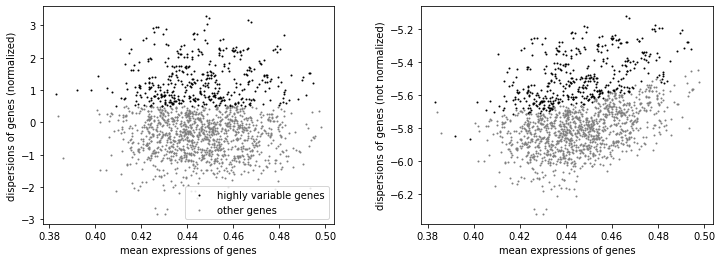

In [18]:
import matplotlib.pyplot as plt
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata, show=False) # can not scale only x

## 3. PCA

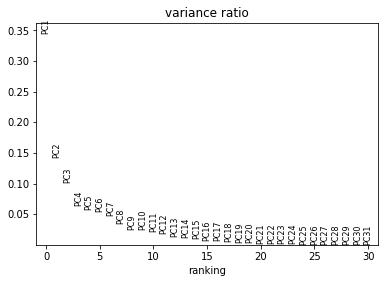

In [19]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata)

## 4. Neighborhood graph and umap

In [20]:
from itertools import product
import seaborn as sns
import matplotlib.pyplot as plt

### Select metric

In [21]:
metrics = [  'sokalmichener', 'sokalsneath', 'yule', 'cosine', 'euclidean', 'l1', 'l2', 'manhattan','braycurtis', 'canberra', 'chebyshev', 'correlation', 'dice', 'hamming', 'jaccard', 'kulsinski', 'mahalanobis', 'minkowski', 'rogerstanimoto', 'russellrao']

metric: sokalmichener (0, 0)
metric: sokalsneath (0, 1)
metric: yule (0, 2)
metric: cosine (0, 3)
metric: euclidean (0, 4)
metric: l1 (1, 0)
metric: l2 (1, 1)
metric: manhattan (1, 2)
metric: braycurtis (1, 3)
metric: canberra (1, 4)
metric: chebyshev (2, 0)
metric: correlation (2, 1)
metric: dice (2, 2)
metric: hamming (2, 3)
metric: jaccard (2, 4)
metric: kulsinski (3, 0)
metric: mahalanobis (3, 1)
metric: minkowski (3, 2)
metric: rogerstanimoto (3, 3)
metric: russellrao (3, 4)


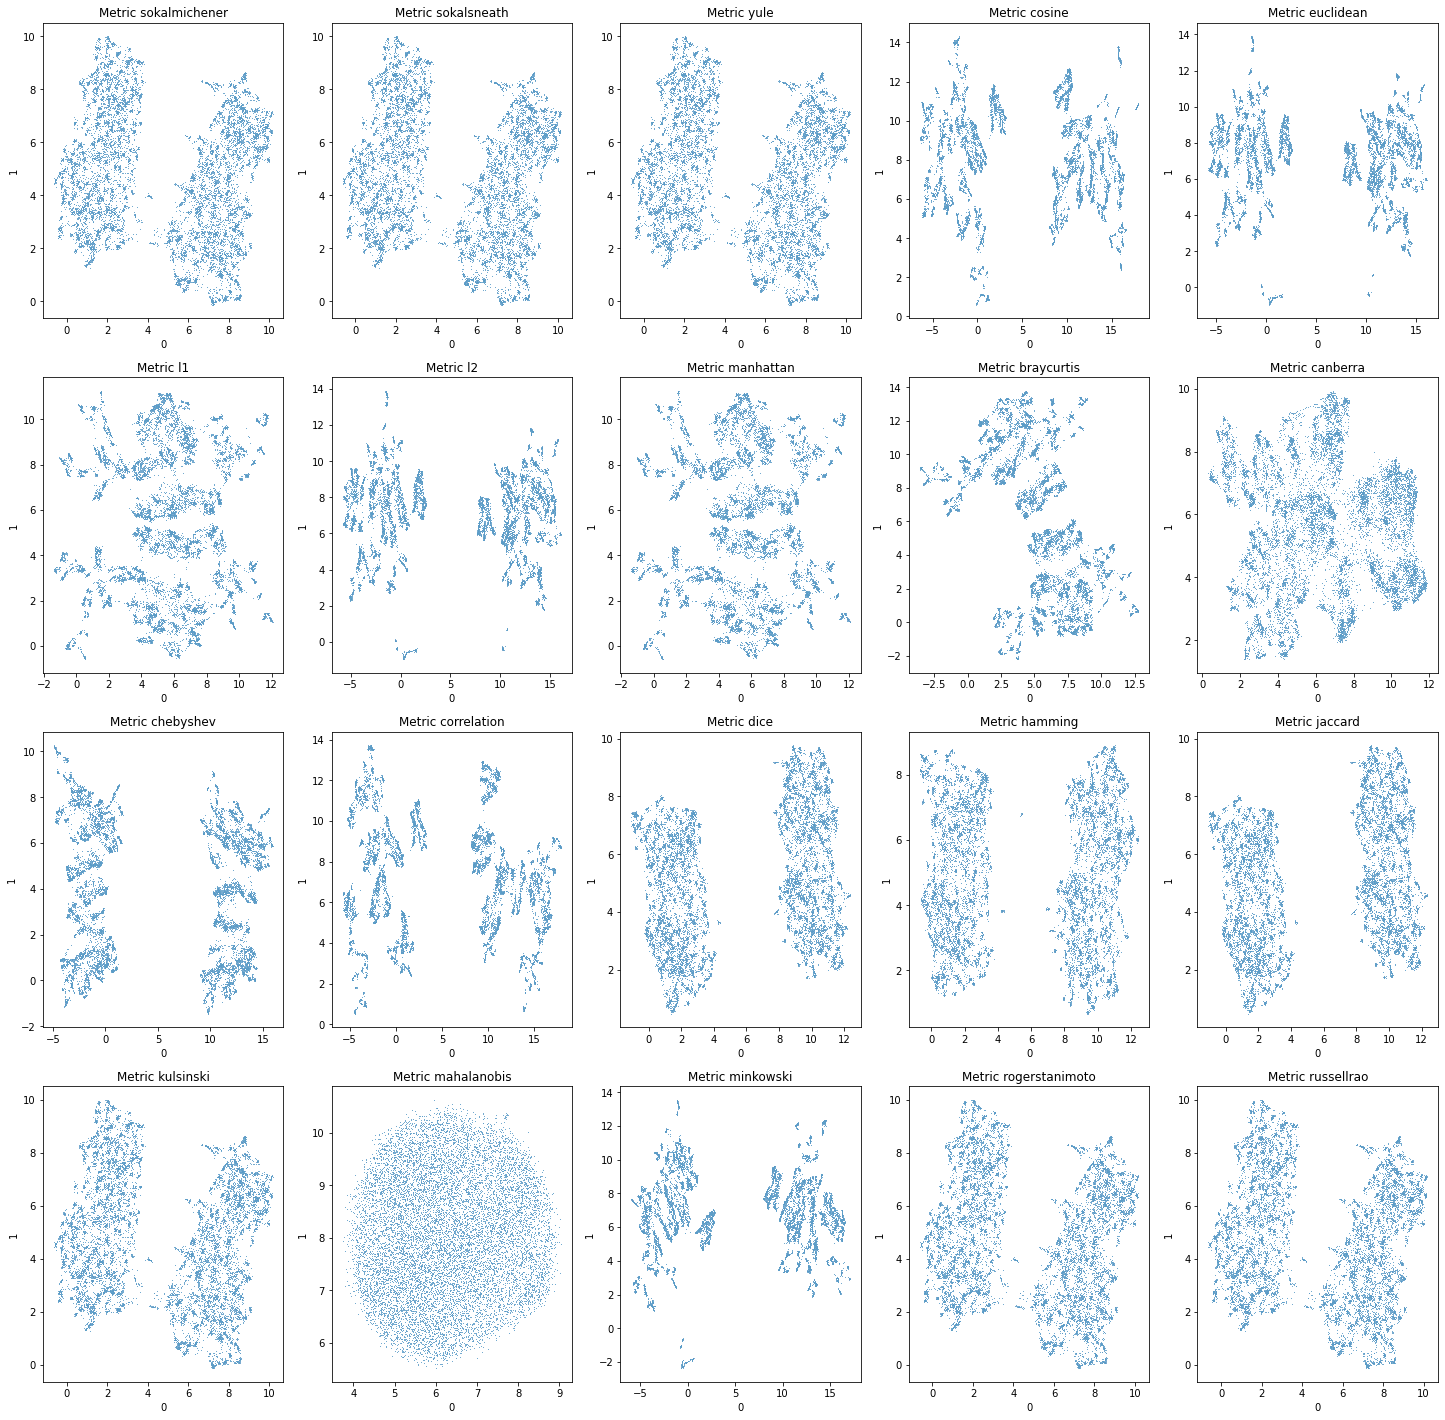

In [22]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25,25))
for coord, metric in zip(product(range(5), range(5)), metrics):
    print("metric:", metric , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric=metric)
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"Metric {metric}")

### Select number of principal components

In [23]:
principal_components = range(5, 30, 5)

In [24]:
list(principal_components)

[5, 10, 15, 20, 25]

In [25]:
len(list(principal_components))

5

n_pcs: 5
n_pcs: 10
n_pcs: 15
n_pcs: 20
n_pcs: 25


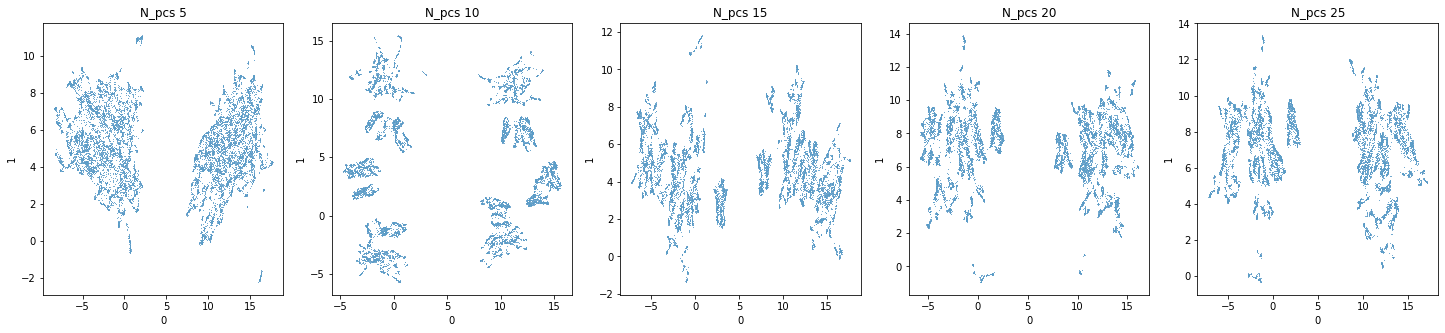

In [26]:
fig, axes = plt.subplots(ncols=5, figsize=(25,5))
for i, n_pcs in enumerate(principal_components):
    print("n_pcs:", n_pcs)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=n_pcs, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[i]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"N_pcs {n_pcs}")

### Select number of neighbours

In [27]:
num_neighbors = range(5, 55, 5)

In [28]:
len(num_neighbors)

10

n_neighbors: 5 (0, 0)
n_neighbors: 10 (0, 1)
n_neighbors: 15 (0, 2)
n_neighbors: 20 (0, 3)
n_neighbors: 25 (0, 4)
n_neighbors: 30 (1, 0)
n_neighbors: 35 (1, 1)
n_neighbors: 40 (1, 2)
n_neighbors: 45 (1, 3)
n_neighbors: 50 (1, 4)


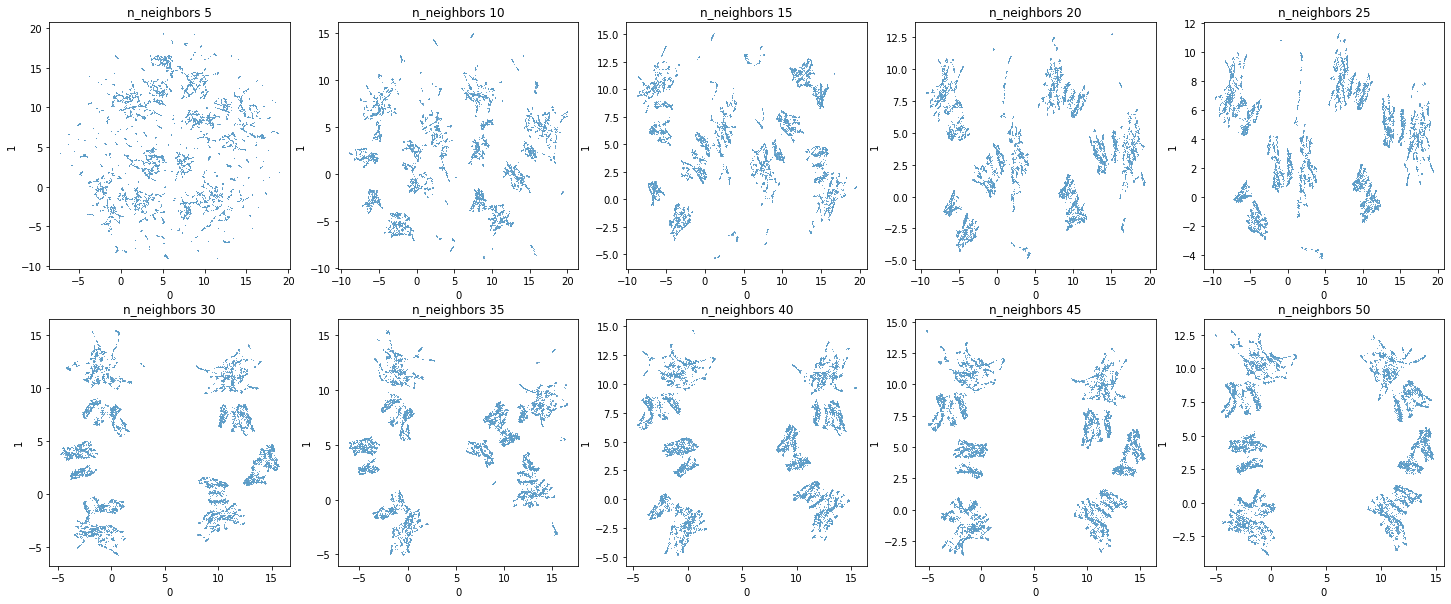

In [29]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, n_neighbors in zip(product(range(2), range(5)), num_neighbors):
    print("n_neighbors:", n_neighbors , coord)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=10, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"n_neighbors {n_neighbors}")


### Select min_dist

In [31]:
min_dists = np.linspace(0.05, 0.5, 10)

min_dist: 0.05 (0, 0)
min_dist: 0.1 (0, 1)
min_dist: 0.15000000000000002 (0, 2)
min_dist: 0.2 (0, 3)
min_dist: 0.25 (0, 4)
min_dist: 0.3 (1, 0)
min_dist: 0.35000000000000003 (1, 1)
min_dist: 0.4 (1, 2)
min_dist: 0.45 (1, 3)
min_dist: 0.5 (1, 4)


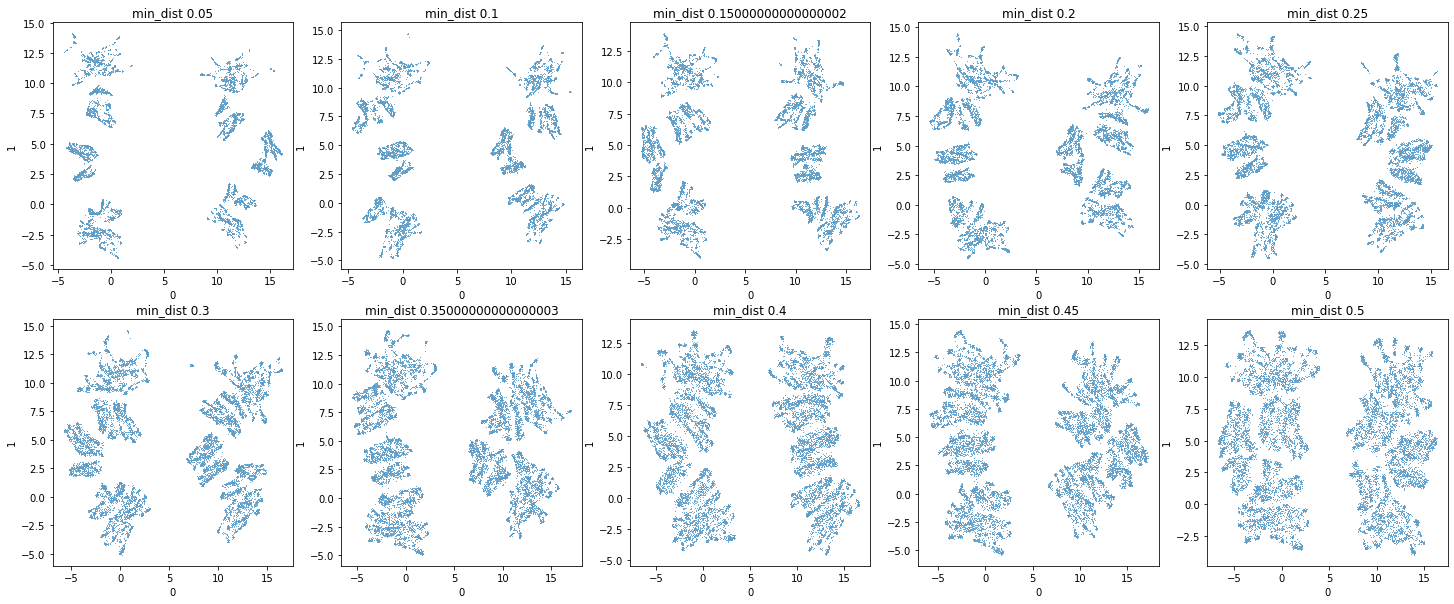

In [32]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, min_dist in zip(product(range(2), range(5)), min_dists):
    print("min_dist:", min_dist , coord)
    sc.pp.neighbors(adata, n_neighbors=40, n_pcs=10, metric='euclidean')
    sc.tl.umap(adata, min_dist=min_dist)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"min_dist {min_dist}")

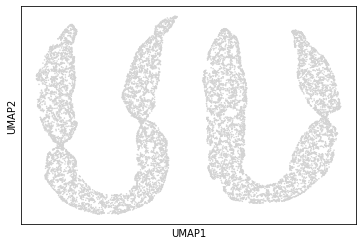

In [46]:
sc.pp.neighbors(adata, n_neighbors=40, n_pcs=2, metric="euclidean")
sc.tl.umap(adata, min_dist=0.3)
sc.pl.umap(adata)

## 5.  Cell clusters

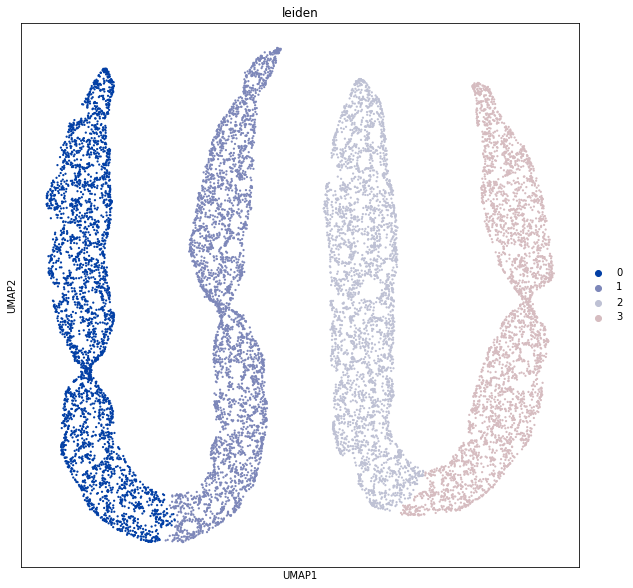

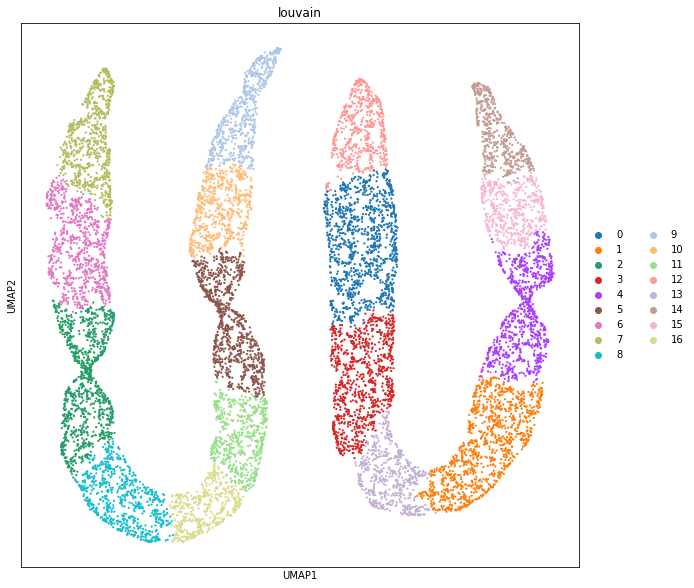

In [50]:
from matplotlib.pyplot import rc_context
with rc_context({'figure.figsize': (10, 10)}):
    sc.tl.leiden(adata, resolution=0.01)
    sc.tl.louvain(adata, resolution=0.7)
    sc.pl.umap(adata, color='leiden', s=20)
    sc.pl.umap(adata, color='louvain', s=20)

<AxesSubplot:xlabel='0', ylabel='1'>

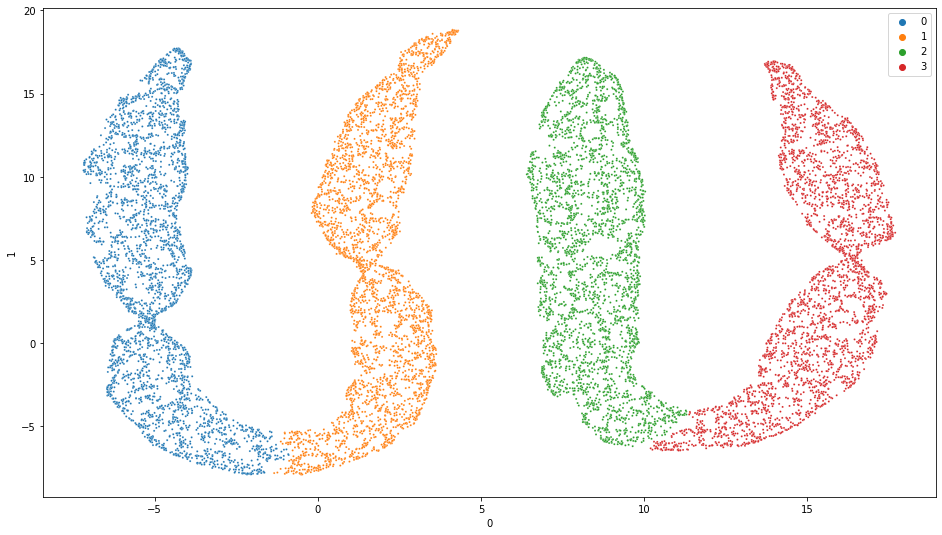

In [51]:
plt.figure(figsize=(16,9))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=4, hue=adata.obs['leiden'].values)

## 6. Color by allele

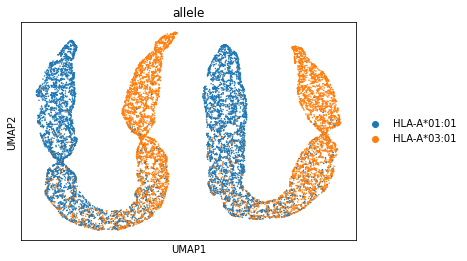

In [47]:
sc.pl.umap(adata, color="allele")

<AxesSubplot:xlabel='0', ylabel='1'>

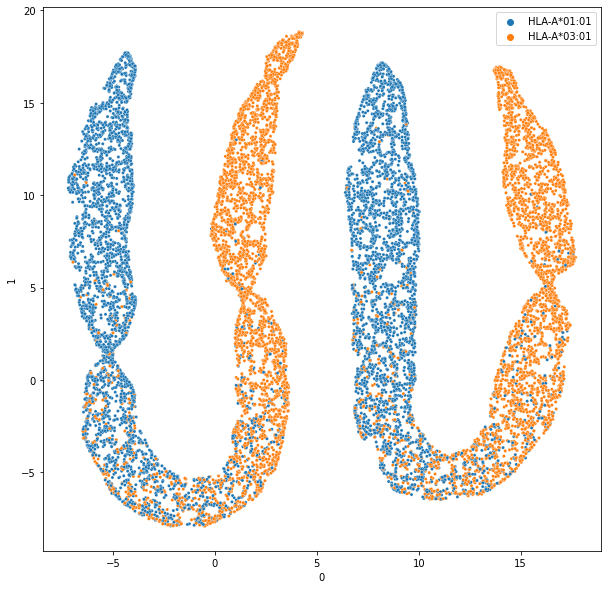

In [52]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata.obs['allele'].values)

## 7. Plot cluster motifs

In [53]:
peptides_df = adata.obs.copy()

In [54]:
import logomaker
def make_logo(df, length=9, cluster_num=0):
    filtered = df[df['length'] == length]
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = dict(df['allele'].value_counts())
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f"Cluster {cluster_num} Allele counts: {counts}")

In [55]:
def plot_all_cluster_motifs(source_df, cluster_column = 'leiden' ):
    unique_clusters = peptides_df[cluster_column].unique()
    for cluster_num in unique_clusters:
        df = source_df[source_df[cluster_column] == cluster_num]
        make_logo(df, cluster_num=cluster_num)

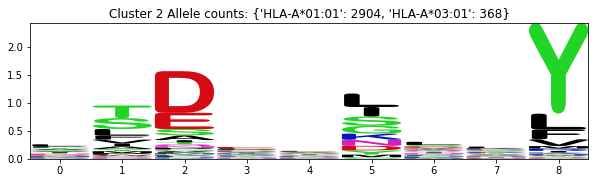

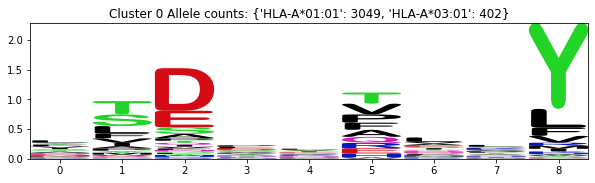

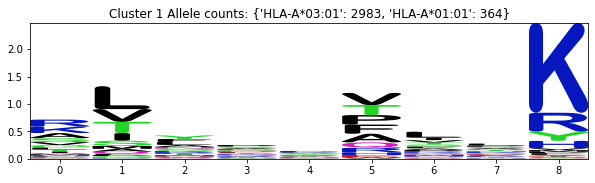

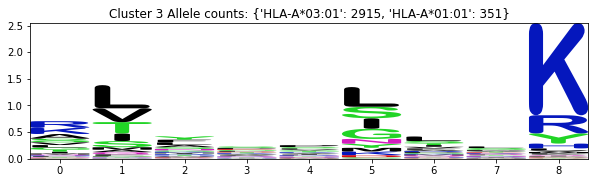

In [56]:
plot_all_cluster_motifs(peptides_df)